In [35]:
import random
import numpy as np
import torch

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

# Usage
set_seed(42)

In [ ]:
%load_ext autoreload
%autoreload 2
from lcb_no_forget import LCB, LCBModel
import os
from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
from collection import Collector
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)
import pickle
import os

# Load the data from the pickle file
output_file_boN = os.path.join(run_dir, 'lcb_and_rs_results_20_value_epochs.pkl')
with open(output_file, 'rb') as f:
    data_lcb_rs = pickle.load(f)
output_file_boN = os.path.join(run_dir, 'lcb_and_rs_results_20_value_epochs.pkl')
with open(output_file, 'rb') as f:
    data_BoN = pickle.load(f)


print("Data loaded successfully.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Data loaded successfully.


In [63]:
output_file_true = os.path.join(run_dir, 'true_distribution_results.pkl')
with open(output_file_true, 'rb') as f:
    data_true = pickle.load(f)

In [39]:
# data_true[1][]
true_dict = {B: {"samples": data_true[B]['X_guided_true'], "effective_N": data_true[B]["num_steps_true"]/(5000*20)} for B in [1, 3, 5]}

In [58]:
data_true["temp_0.2"]["samples"].shape

(20, 7000, 2)

In [47]:
temp = 0.2
true_dict[round(1/temp, 0)]["samples"].shape

(5000, 20, 2)

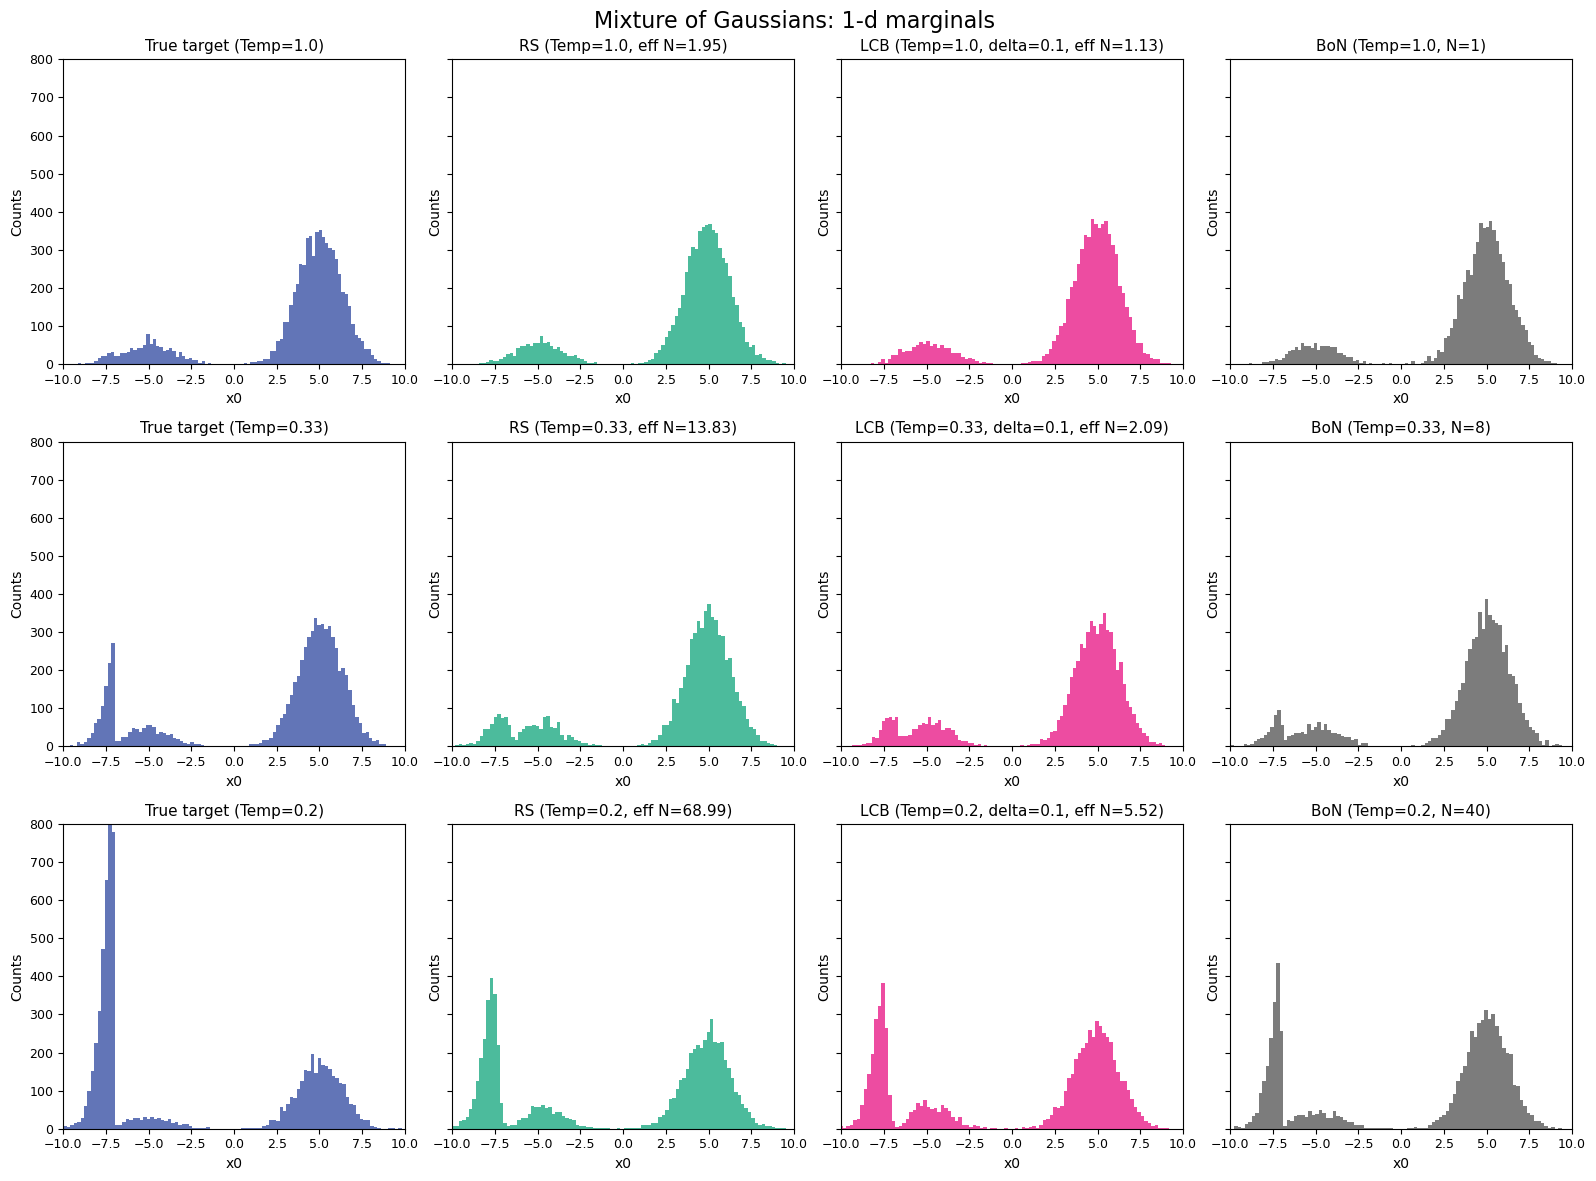

In [142]:
import pickle
import os
import matplotlib.pyplot as plt
import numpy as np
from collection import Collector
from nets import load_val_estimate

# User-specified parameters
BoN_Ns = [1, 8, 40]  # Example: list of 3 integers
delta = 0.1  # Example: single float for LCB delta

run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)

# Load BoN results
with open(os.path.join(run_dir, 'bon_results.pkl'), 'rb') as f:
    BoN_sets = pickle.load(f)

# Load LCB and RS results
with open(os.path.join(run_dir, 'lcb_and_rs_results_20_value_epochs.pkl'), 'rb') as f:
    lcb_rs_data = pickle.load(f)

# Temperatures
temps = [1.0, 0.33, 0.2]
temp_keys = ['temp_1.0', 'temp_0.2', 'temp_0.33']
delta_key = f'lcb_delta_{delta}'

# Create 3x4 subplot grid (rows correspond to temperature/BoN_N pairs)
fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharey='row', sharex="row")
fig.suptitle('Mixture of Gaussians: 1-d marginals', fontsize=16)

lim = (-10, 10)
ylim = (-5, 5)
hist_xlim = (-10, 10)
hist_ylim = (0, 800)

for i, (temp, N) in enumerate(zip(temps, BoN_Ns)):
    temp_key = f'temp_{str(temp)}'
    
    # Load core and value estimator for this temp
    value_estimator, states, index_set, _ = load_val_estimate(run_id, temp, device="mps", file_name=f"value_net_temp_{str(temp).replace('.', 'p')}_20_epochs")
    collector = Collector(None, None)
    core, _, _ = collector.load_collected(run_dir)
    core.S = 7000
    
    # Load RS and LCB data
    rs_samples = lcb_rs_data[temp_key]['rs_samples'][0, :, 0]  # x0 for RS
    lcb_samples = lcb_rs_data[temp_key][delta_key]['samples'][:, 0]  # x0 for LCB
    rs_effective_N = round(lcb_rs_data[temp_key]['rs_effective_N'], 2)
    lcb_effective_N = round(lcb_rs_data[temp_key][delta_key]['effective_N'], 2)
    
    # Unguided: Generate samples
    # X_unguided = core.collect_run()[0, :, 0]  # x0
    X_true = data_true[temp_key]["samples"]
    
    # BoN: From saved data
    bon_samples = BoN_sets[N][:, 0]  # x0
    
    # Plot Unguided (col 0)
    axes[i, 0].hist(X_true[:, 0], bins=100, density=False, alpha=0.7, color='#1f3b99')
    axes[i, 0].set_title(f'True target (Temp={temp})')
    axes[i, 0].set_xlabel('x0')
    axes[i, 0].set_ylabel('Counts')
    axes[i, 0].set_xlim(hist_xlim)
    axes[i, 0].set_ylim(hist_ylim)
    
    # Plot RS (col 1)
    axes[i, 1].hist(rs_samples, bins=100, density=False, alpha=0.7, color='#009e73')
    axes[i, 1].set_title(f'RS (Temp={temp}, eff N={rs_effective_N})')
    axes[i, 1].set_xlabel('x0')
    axes[i, 1].set_ylabel('Counts')
    
    # Plot LCB (col 2)
    axes[i, 2].hist(lcb_samples, bins=100, density=False, alpha=0.7, color='#e6007a')
    axes[i, 2].set_title(f'LCB (Temp={temp}, delta={delta}, eff N={lcb_effective_N})')
    axes[i, 2].set_xlabel('x0')
    axes[i, 2].set_ylabel('Counts')
    
    # Plot BoN (col 3)
    axes[i, 3].hist(bon_samples, bins=100, density=False, alpha=0.7, color='#444444')
    axes[i, 3].set_title(f'BoN (Temp={temp}, N={N})')
    axes[i, 3].set_xlabel('x0')
    axes[i, 3].set_ylabel('Counts')

plt.tight_layout()
plt.show()

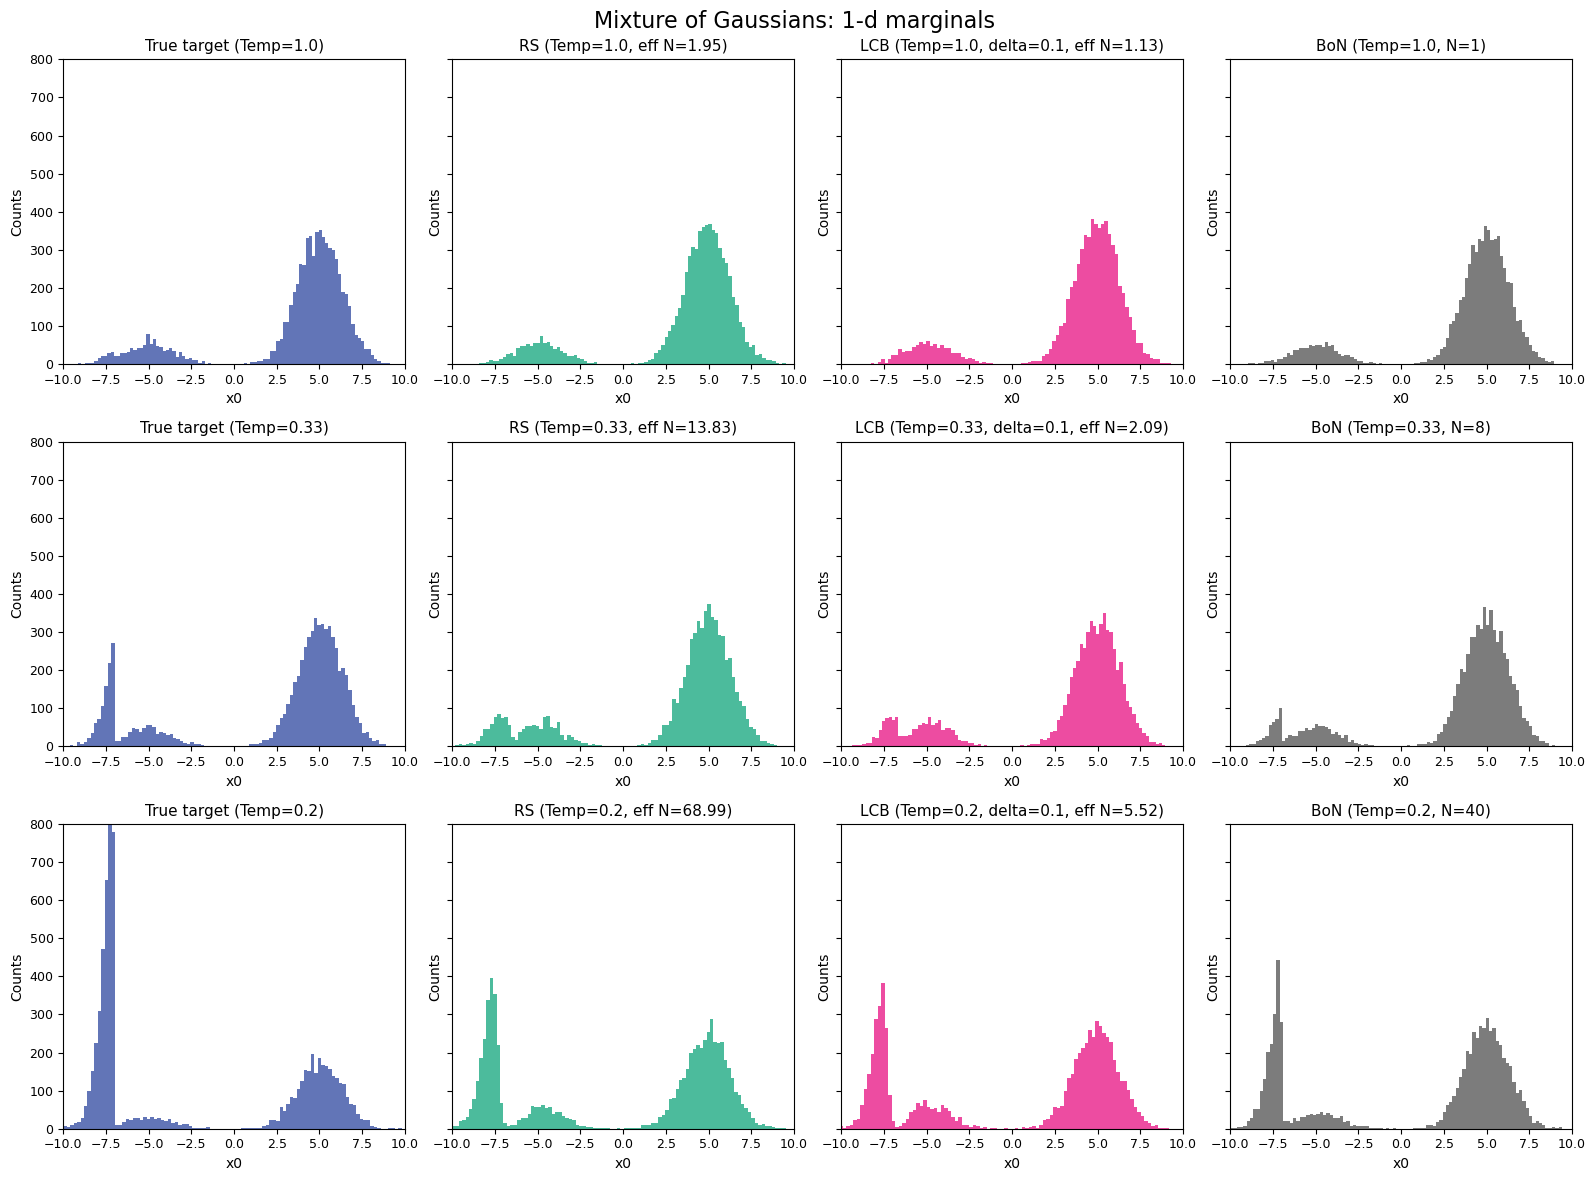

In [160]:
import pickle
import os
import matplotlib.pyplot as plt
import numpy as np
from collection import Collector
from nets import load_val_estimate

# User-specified parameters
BoN_Ns = [1, 8, 40]  # Example: list of 3 integers
delta = 0.1 # Example: single float for LCB delta

run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)

# Load BoN results
with open(os.path.join(run_dir, 'bon_results.pkl'), 'rb') as f:
    BoN_sets = pickle.load(f)

# Load LCB and RS results
with open(os.path.join(run_dir, 'lcb_and_rs_results_20_value_epochs.pkl'), 'rb') as f:
    lcb_rs_data = pickle.load(f)

# Temperatures
temps = [1.0, 0.33, 0.2]
temp_keys = ['temp_1.0', 'temp_0.2', 'temp_0.33']
delta_key = f'lcb_delta_{delta}'

# Create 3x4 subplot grid (rows correspond to temperature/BoN_N pairs)
fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharey='row', sharex="row")
fig.suptitle('Mixture of Gaussians: 1-d marginals', fontsize=16)

lim = (-10, 10)
ylim = (-5, 5)
hist_xlim = (-10, 10)
hist_ylim = (0, 800)

for i, (temp, N) in enumerate(zip(temps, BoN_Ns)):
    temp_key = f'temp_{str(temp)}'
    
    # Load core and value estimator for this temp
    value_estimator, states, index_set, _ = load_val_estimate(run_id, temp, device="mps", file_name=f"value_net_temp_{str(temp).replace('.', 'p')}_20_epochs")
    collector = Collector(None, None)
    core, _, _ = collector.load_collected(run_dir)
    core.S = 7000
    
    # Load RS and LCB data
    rs_samples = lcb_rs_data[temp_key]['rs_samples'][0, :, 0]  # x0 for RS
    lcb_samples = lcb_rs_data[temp_key][delta_key]['samples'][:, 0]  # x0 for LCB
    rs_effective_N = round(lcb_rs_data[temp_key]['rs_effective_N'], 2)
    lcb_effective_N = round(lcb_rs_data[temp_key][delta_key]['effective_N'], 2)
    
    # Unguided: Generate samples
    # X_unguided = core.collect_run()[0, :, 0]  # x0
    X_true = data_true[temp_key]["samples"]
    
    # BoN: From saved data
    bon_samples = BoN_sets[N][:, 0]  # x0
    
    # Plot Unguided (col 0)
    axes[i, 0].hist(X_true[:, 0], bins=100, density=False, alpha=0.7, color='#1f3b99')
    axes[i, 0].set_title(f'True target (Temp={temp})')
    axes[i, 0].set_xlabel('x0')
    axes[i, 0].set_ylabel('Counts')
    axes[i, 0].set_xlim(hist_xlim)
    axes[i, 0].set_ylim(hist_ylim)
    
    # Plot RS (col 1)
    axes[i, 1].hist(rs_samples, bins=100, density=False, alpha=0.7, color='#009e73')
    axes[i, 1].set_title(f'RS (Temp={temp}, eff N={rs_effective_N})')
    axes[i, 1].set_xlabel('x0')
    axes[i, 1].set_ylabel('Counts')
    
    # Plot LCB (col 2)
    axes[i, 2].hist(lcb_samples, bins=100, density=False, alpha=0.7, color='#e6007a')
    axes[i, 2].set_title(f'LCB (Temp={temp}, delta={delta}, eff N={lcb_effective_N})')
    axes[i, 2].set_xlabel('x0')
    axes[i, 2].set_ylabel('Counts')
    
    # Plot BoN (col 3)
    axes[i, 3].hist(bon_samples, bins=100, density=False, alpha=0.7, color='#444444')
    axes[i, 3].set_title(f'BoN (Temp={temp}, N={N})')
    axes[i, 3].set_xlabel('x0')
    axes[i, 3].set_ylabel('Counts')

plt.tight_layout()
plt.show()

In [151]:
lcb_rs_data["temp_0.2"]['lcb_delta_0.005']['effective_N']

7.2240142857142855

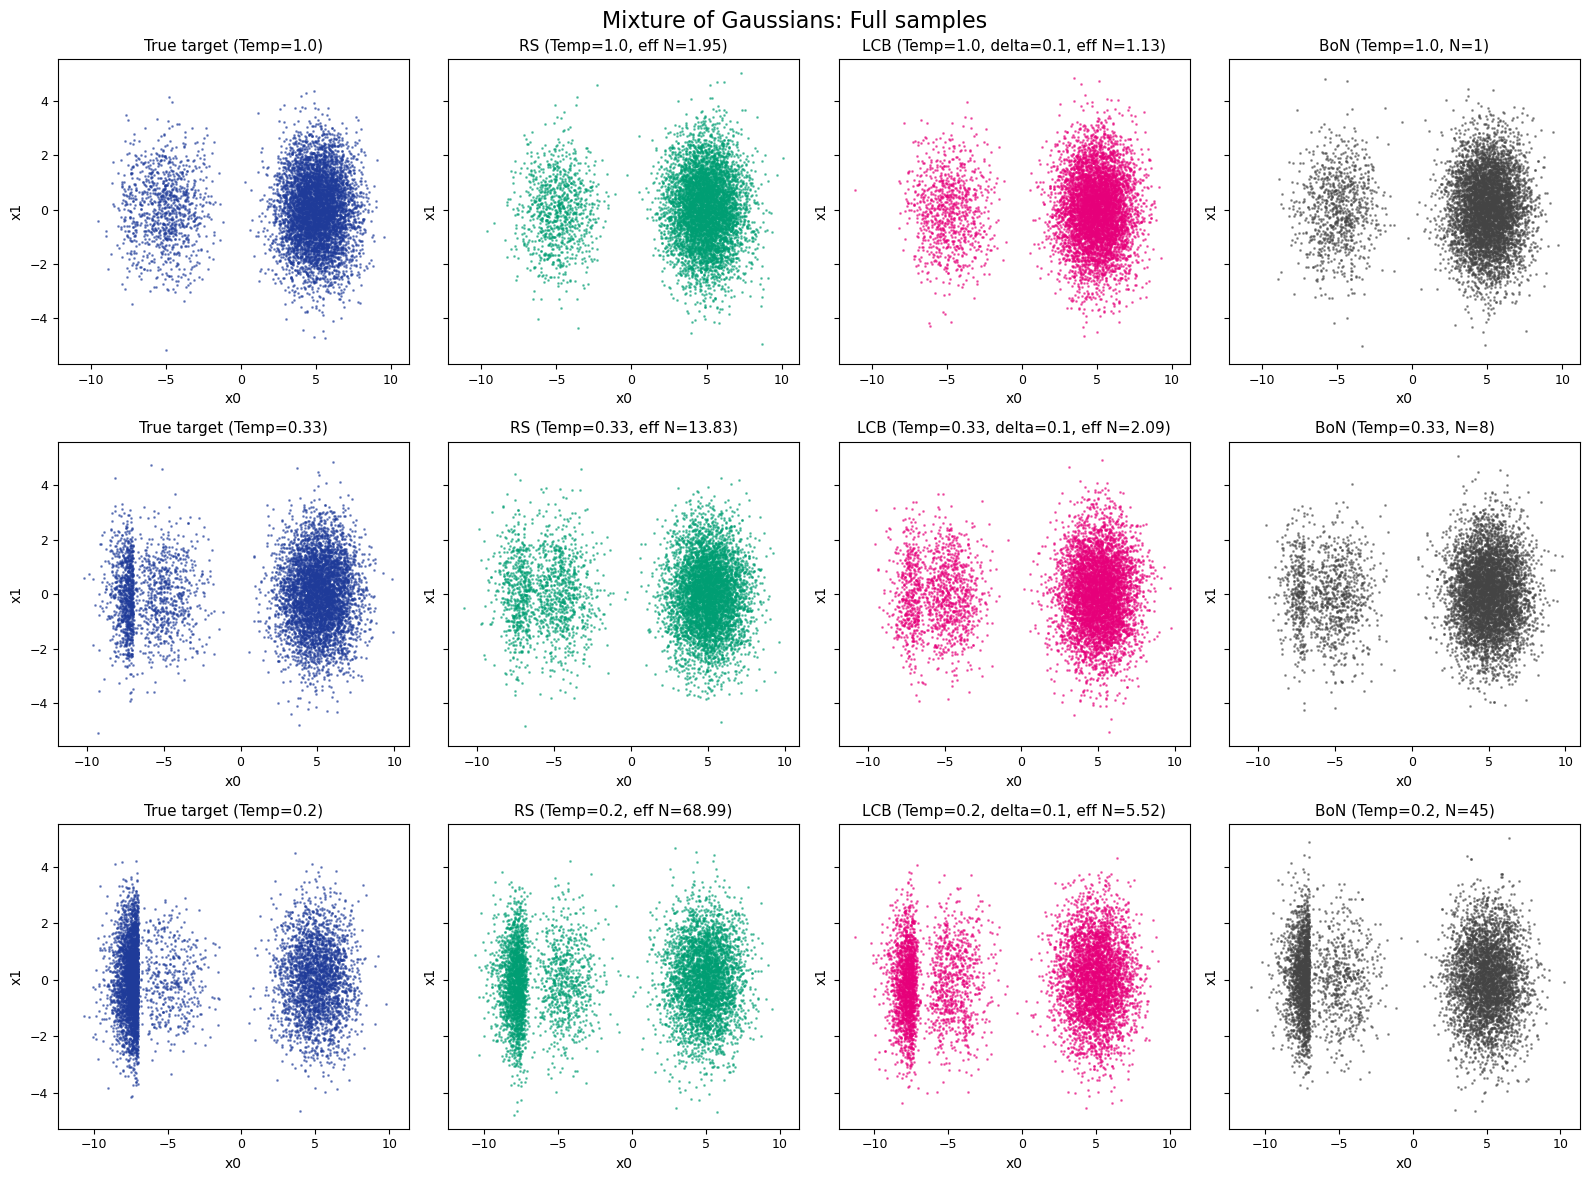

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# User-specified parameters
BoN_Ns = [1, 8, 40] 
delta = 0.1 

# Load BoN results
with open(os.path.join(run_dir, 'bon_results.pkl'), 'rb') as f:
    BoN_sets = pickle.load(f)

run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)

temps = [1.0, 0.33, 0.2]
temp_keys = ['temp_1.0', 'temp_0.2', 'temp_0.33']
delta_key = f'lcb_delta_{delta}'

fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharey='row', sharex="row")
fig.suptitle('Mixture of Gaussians: Full samples', fontsize=16)

for i, (temp, N) in enumerate(zip(temps, BoN_Ns)):
    temp_key = f'temp_{str(temp)}'
    
    rs_samples = lcb_rs_data[temp_key]['rs_samples'][0, :, :]  # (7000, 2) for RS
    lcb_samples = lcb_rs_data[temp_key][delta_key]['samples']  # (7000, 2) for LCB
    rs_effective_N = round(lcb_rs_data[temp_key]['rs_effective_N'], 2)
    lcb_effective_N = round(lcb_rs_data[temp_key][delta_key]['effective_N'], 2)
    
    # True samples
    X_true = data_true[temp_key]["samples"]  # (7000, 2)
    
    # BoN: From saved data
    bon_samples = BoN_sets[N]  # (7000, 2)
    
    # Plot True (col 0)
    axes[i, 0].scatter(X_true[:, 0], X_true[:, 1], alpha=0.5, color='#1f3b99', s=1)
    axes[i, 0].set_title(f'True target (Temp={temp})')
    axes[i, 0].set_xlabel('x0')
    axes[i, 0].set_ylabel('x1')
    
    # Plot RS (col 1)
    axes[i, 1].scatter(rs_samples[:, 0], rs_samples[:, 1], alpha=0.5, color='#009e73', s=1)
    axes[i, 1].set_title(f'RS (Temp={temp}, eff N={rs_effective_N})')
    axes[i, 1].set_xlabel('x0')
    axes[i, 1].set_ylabel('x1')
    
    # Plot LCB (col 2)
    axes[i, 2].scatter(lcb_samples[:, 0], lcb_samples[:, 1], alpha=0.5, color='#e6007a', s=1)
    axes[i, 2].set_title(f'LCB (Temp={temp}, delta={delta}, eff N={lcb_effective_N})')
    axes[i, 2].set_xlabel('x0')
    axes[i, 2].set_ylabel('x1')
    
    # Plot BoN (col 3)
    axes[i, 3].scatter(bon_samples[:, 0], bon_samples[:, 1], alpha=0.5, color='#444444', s=1)
    axes[i, 3].set_title(f'BoN (Temp={temp}, N={N})')
    axes[i, 3].set_xlabel('x0')
    axes[i, 3].set_ylabel('x1')

plt.tight_layout()
plt.show()

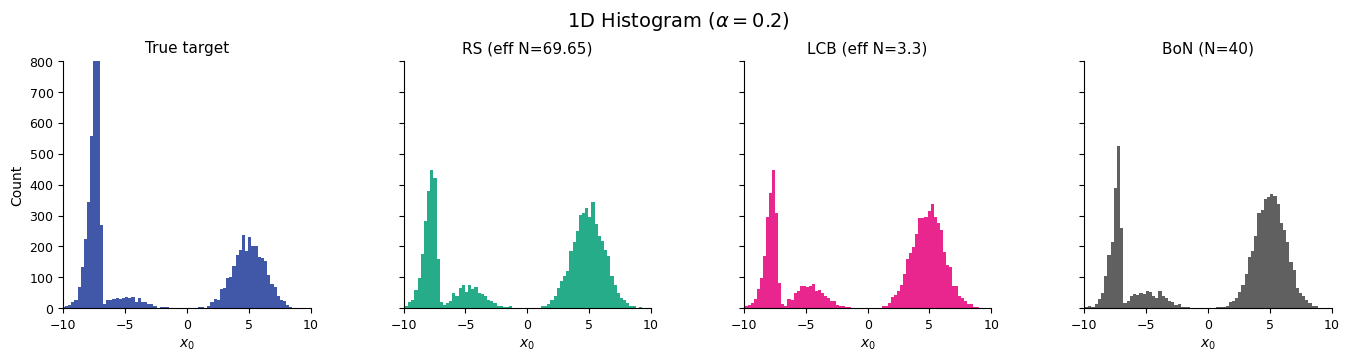

In [77]:
import matplotlib.pyplot as plt

# ICML-ish defaults
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

fig, axes = plt.subplots(
    1, 4,
    figsize=(14, 3.5),          # 🔧 wide & short (not 12x12)
    sharex=True,
    sharey=True,
    constrained_layout=True     # 🔧 better than tight_layout
)

fig.suptitle(rf'1D Histogram ($\alpha = 0.2$)', fontsize=14)

hist_xlim = (-10, 10)
hist_ylim = (0, 800)
bins = 80                       # 🔧 fewer bins = cleaner

# --- True target ---
axes[0].hist(
    X_true[:, 0],
    bins=bins,
    density=False,
    alpha=0.85,
    color='#1f3b99',
    linewidth=0
)
axes[0].set_title('True target')
axes[0].set_ylabel('Count')

# --- RS ---
axes[1].hist(
    rs_samples,
    bins=bins,
    density=False,
    alpha=0.85,
    color='#009e73',
    linewidth=0
)
axes[1].set_title(f'RS (eff N={rs_effective_N})')

# --- LCB ---
axes[2].hist(
    lcb_samples,
    bins=bins,
    density=False,
    alpha=0.85,
    color='#e6007a',
    linewidth=0
)
axes[2].set_title(f'LCB (eff N={lcb_effective_N})')  # 🔧 fixed paren

# --- BoN ---
axes[3].hist(
    bon_samples,
    bins=bins,
    density=False,
    alpha=0.85,
    color='#444444',
    linewidth=0
)
axes[3].set_title(f'BoN (N={N})')

# --- Shared formatting ---
for ax in axes:
    ax.set_xlim(hist_xlim)
    ax.set_ylim(hist_ylim)
    ax.set_xlabel('$x_0$')
    ax.set_box_aspect(1)        # 🔥 makes panels square
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.show()


In [91]:
import pickle
import os

# Load LCB plus BoN results
with open(os.path.join(run_dir, 'lcb_plus_BoN.pkl'), 'rb') as f:
    BoN_sets_lcb = pickle.load(f)

print("LCB plus BoN results loaded successfully.")

LCB plus BoN results loaded successfully.


/var/folders/zk/bk5jkrk11398bfvxps9gbhw00000gn/T/ipykernel_66461/1111578097.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.92])


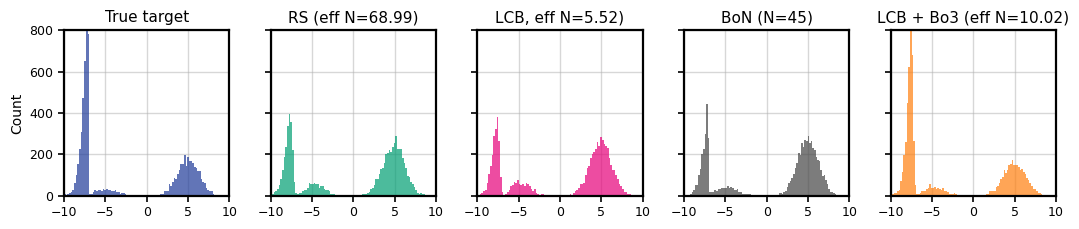

In [159]:
lcb_samples = lcb_rs_data["temp_0.2"]['lcb_delta_0.1']['samples'][:, 0]  # x0 for LCB
rs_samples = lcb_rs_data["temp_0.2"]['rs_samples'][0, :, 0]  # x0 for RS
rs_effective_N = round(lcb_rs_data["temp_0.2"]['rs_effective_N'], 2)
lcb_effective_N = round(lcb_rs_data["temp_0.2"]['lcb_delta_0.1']['effective_N'], 2)
bon_samples = BoN_sets[40][:, 0]  # x0
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# --- Layout: control spacing explicitly (key fix) ---
fig, axes = plt.subplots(
    1, 5,
    figsize=(12.8, 3.0),
    sharex=True,
    sharey=True,
    gridspec_kw=dict(wspace=0.25)  # <-- pack panels like the reference
)

# fig.suptitle(r'1d Histogram ($\alpha = 0.2$)', fontsize=14)

hist_xlim = (-10, 10)
hist_ylim = (0, 800)

# ---- Your original plotting (kept the same) ----
axes[0].hist(X_true[:, 0], bins=100, density=False, alpha=0.7, color='#1f3b99')
axes[0].set_title('True target')
axes[0].set_ylabel('Count')  # <-- match what you're plotting

axes[1].hist(rs_samples, bins=100, density=False, alpha=0.7, color='#009e73')
axes[1].set_title(f'RS (eff N={rs_effective_N})')

axes[2].hist(lcb_samples, bins=100, density=False, alpha=0.7, color='#e6007a')
axes[2].set_title(f'LCB, eff N={lcb_effective_N})')

axes[3].hist(bon_samples, bins=100, density=False, alpha=0.7, color='#444444')
axes[3].set_title(f'BoN (N={N})')


axes[4].hist(BoN_sets_lcb[3]["samples"][:, 0], bins=100, density=False, alpha=0.7, color='#ff7f0e')
axes[4].set_title(f'LCB + Bo3 (eff N={round(BoN_sets_lcb[3]["eff N"], 2)})')

# ---- Panel styling to match reference ----
for ax in axes:
    ax.set_xlim(hist_xlim)
    ax.set_ylim(hist_ylim)

    # square panels
    ax.set_box_aspect(1)

    # ticks like the reference
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.yaxis.set_major_locator(MultipleLocator(200))

    # boxed axes + slightly heavier lines
    for spine in ax.spines.values():
        spine.set_linewidth(1.6)

    ax.tick_params(direction="out", length=4, width=1.2)

    # light gray grid
    ax.set_axisbelow(True)
    ax.grid(True, which="major", linewidth=1.0, alpha=0.5)

# remove repeated y-labels (reference only labels the left panel)
for ax in axes[1:]:
    ax.set_ylabel("")

# reserve top space for suptitle (prevents layout weirdness)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

fig.savefig("hist_strip_icml.pdf", bbox_inches="tight")

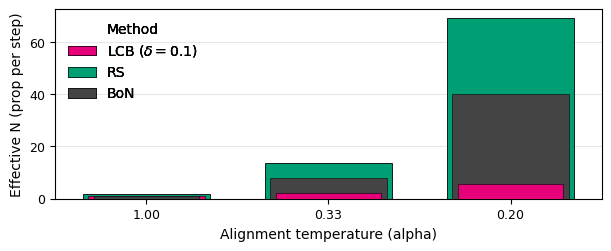

In [146]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Load data
# ----------------------------
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)

delta = 0.1
delta_key = f"lcb_delta_{delta}"

with open(os.path.join(run_dir, "lcb_and_rs_results_20_value_epochs.pkl"), "rb") as f:
    lcb_rs_data = pickle.load(f)

temps = [1.0, 0.33, 0.2]
bon_N_by_temp = {1.0: 1, 0.33: 8, 0.2: 40}  # proposals per step for BoN

# Methods in the same style as the reference code
methods = ["LCB", "RS", "BoN"]
colors = {
    "LCB": "#e6007a",
    "RS": "#009e73",
    "BoN": "#444444",
}

# Build Y: shape (len(temps), 3) with columns [chern, rs, bon]
Y = []
for t in temps:
    temp_key = f"temp_{t}"
    ch = float(lcb_rs_data[temp_key][delta_key]["effective_N"])
    rs = float(lcb_rs_data[temp_key]["rs_effective_N"])
    bon = float(bon_N_by_temp[t])
    Y.append([ch, rs, bon])

Y = np.array(Y)

# ----------------------------
# PLOT: nested "buildings" (all start at 0), widths increase with height rank
# ----------------------------
x = np.arange(len(temps))

fig, ax = plt.subplots(figsize=(6.0, 2.4), constrained_layout=True)

w_min, w_max = 0.58, 0.70
widths = np.linspace(w_min, w_max, 3)  # low, mid, high (by rank)

for i in range(len(temps)):
    vals = Y[i]              # [chern, rs, bon]
    order = np.argsort(vals) # low -> high indices

    # draw widest (tallest) first so narrower ones remain visible on top
    for rank in [2, 1, 0]:   # high, mid, low
        idx = order[rank]
        m = methods[idx]
        ax.bar(
            x[i],
            vals[idx],            # full height from 0
            bottom=0.0,
            width=widths[rank],   # width encodes rank
            color=colors[m],
            edgecolor="black",
            linewidth=0.6 if rank == 2 else 0.4,
            zorder=2 + (2 - rank),
            align="center",
        )

# ----------------------------
# Axes formatting
# ----------------------------
ax.set_xlabel("Alignment temperature (alpha)")
ax.set_ylabel("Effective N (prop per step)")
ax.grid(True, axis="y", alpha=0.3, zorder=0)

ax.set_xticks(x)
ax.set_xticklabels([f"{t:.2f}" if t != 1.0 else "1.00" for t in temps])
ax.set_xlim(-0.5, len(temps) - 0.5)

# Legend labels
method_labels = {
    "LCB": rf"LCB ($\delta={delta}$)",
    "RS": "RS",
    "BoN": "BoN",
}

method_handles = [
    plt.Rectangle((0, 0), 1, 1, color=colors[m], ec="black", lw=0.4)
    for m in methods
]

leg1 = ax.legend(
    method_handles,
    [method_labels[m] for m in methods],
    title="Method",
    frameon=False,
    loc="upper left",
)
ax.add_artist(leg1)

ax.add_artist(leg1)

plt.show()

fig.savefig(f"effective_N_nested_buildings_delta_{str(delta)}.pdf", bbox_inches="tight")
fig.savefig("effectiveN_nested_buildings.png", dpi=400, bbox_inches="tight")


In [ ]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Load data
# ----------------------------
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)

delta = 0.3
delta_key = f"lcb_delta_{delta}"

with open(os.path.join(run_dir, "lcb_and_rs_results_20_value_epochs.pkl"), "rb") as f:
    lcb_rs_data = pickle.load(f)

temps = [1.0, 0.33, 0.2]
bon_N_by_temp = {1.0: 1, 0.33: 8, 0.2: 40}  # proposals per step for BoN

# Methods in the same style as the reference code
methods = ["LCB", "RS", "BoN"]
colors = {
    "LCB": "#e6007a",
    "RS": "#009e73",
    "BoN": "#444444",
}

# Build Y: shape (len(temps), 3) with columns [chern, rs, bon]
Y = []
for t in temps:
    temp_key = f"temp_{t}"
    ch = float(lcb_rs_data[temp_key][delta_key]["effective_N"])
    rs = float(lcb_rs_data[temp_key]["rs_effective_N"])
    bon = float(bon_N_by_temp[t])
    Y.append([ch, rs, bon])

Y = np.array(Y)

# ----------------------------
# PLOT: nested "buildings" (all start at 0), widths increase with height rank
# ----------------------------
x = np.arange(len(temps))

fig, ax = plt.subplots(figsize=(6.0, 2.4), constrained_layout=True)

w_min, w_max = 0.58, 0.70
widths = np.linspace(w_min, w_max, 3)  # low, mid, high (by rank)

for i in range(len(temps)):
    vals = Y[i]              # [chern, rs, bon]
    order = np.argsort(vals) # low -> high indices

    # draw widest (tallest) first so narrower ones remain visible on top
    for rank in [2, 1, 0]:   # high, mid, low
        idx = order[rank]
        m = methods[idx]
        ax.bar(
            x[i],
            vals[idx],            # full height from 0
            bottom=0.0,
            width=widths[rank],   # width encodes rank
            color=colors[m],
            edgecolor="black",
            linewidth=0.6 if rank == 2 else 0.4,
            zorder=2 + (2 - rank),
            align="center",
        )

# ----------------------------
# Axes formatting
# ----------------------------
ax.set_xlabel("Alignment temperature (alpha)")
ax.set_ylabel("Effective N (prop per step)")
ax.grid(True, axis="y", alpha=0.3, zorder=0)

ax.set_xticks(x)
ax.set_xticklabels([f"{t:.2f}" if t != 1.0 else "1.00" for t in temps])
ax.set_xlim(-0.5, len(temps) - 0.5)

# Legend labels
method_labels = {
    "LCB": rf"LCB ($\delta={delta}$)",
    "RS": "RS",
    "BoN": "BoN",
}

method_handles = [
    plt.Rectangle((0, 0), 1, 1, color=colors[m], ec="black", lw=0.4)
    for m in methods
]

leg1 = ax.legend(
    method_handles,
    [method_labels[m] for m in methods],
    title="Method",
    frameon=False,
    loc="upper left",
)
ax.add_artist(leg1)

ax.add_artist(leg1)

plt.show()

fig.savefig(f"effective_N_nested_buildings_delta_{str(delta)}.pdf", bbox_inches="tight")
fig.savefig("effectiveN_nested_buildings.png", dpi=400, bbox_inches="tight")


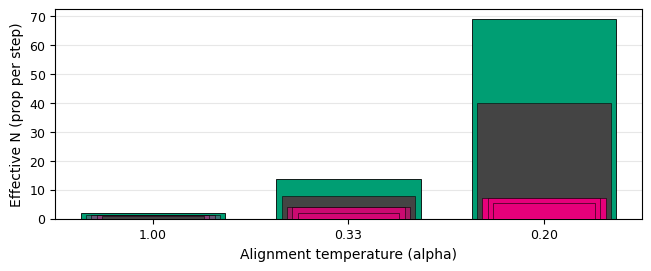

In [147]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# ----------------------------
# Load data
# ----------------------------
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)

with open(os.path.join(run_dir, "lcb_and_rs_results_20_value_epochs.pkl"), "rb") as f:
    lcb_rs_data = pickle.load(f)

temps = [1.0, 0.33, 0.2]
bon_N_by_temp = {1.0: 1, 0.33: 8, 0.2: 40}

# List of deltas to plot (edit this)
deltas = [0.1, 0.005, 0.005]

# Colors
LCB_PINK = "#e6007a"
colors = {
    "RS": "#009e73",
    "BoN": "#444444",
}

# ----------------------------
# Precompute alpha scaling for LCB across ALL temps/deltas
# "proposal complexity" -> map effective_N to alpha
# ----------------------------
lcb_all = []
for t in temps:
    temp_key = f"temp_{t}"
    for d in deltas:
        dk = f"lcb_delta_{d}"
        lcb_all.append(float(lcb_rs_data[temp_key][dk]["effective_N"]))

lcb_all = np.array(lcb_all)
lcb_min, lcb_max = float(lcb_all.min()), float(lcb_all.max())

def lcb_alpha(effN, a_min=0.25, a_max=1.0):
    if lcb_max == lcb_min:
        return a_max
    u = (effN - lcb_min) / (lcb_max - lcb_min)
    return a_min + u * (a_max - a_min)

# ----------------------------
# Build per-temp values: includes ALL LCB deltas + RS + BoN
# ----------------------------
# For each temp i: entries = [("LCB", delta, value, colorRGBA), ..., ("RS", None, value, color), ("BoN", None, value, color)]
per_temp_entries = []
for t in temps:
    temp_key = f"temp_{t}"
    entries = []

    # LCB variants
    for d in deltas:
        dk = f"lcb_delta_{d}"
        effN = float(lcb_rs_data[temp_key][dk]["effective_N"])
        a = lcb_alpha(effN)
        rgba = mcolors.to_rgba(LCB_PINK, alpha=a)
        entries.append(("LCB", d, effN, rgba))

    # RS / BoN
    rs = float(lcb_rs_data[temp_key]["rs_effective_N"])
    bon = float(bon_N_by_temp[t])
    entries.append(("RS", None, rs, colors["RS"]))
    entries.append(("BoN", None, bon, colors["BoN"]))

    per_temp_entries.append(entries)

# ----------------------------
# PLOT: nested "buildings" (all start at 0), widths increase with height rank
# ----------------------------
x = np.arange(len(temps))
fig, ax = plt.subplots(figsize=(6.4, 2.6), constrained_layout=True)

n_bars = len(deltas) + 2  # LCB(deltas) + RS + BoN
w_min, w_max = 0.52, 0.74
widths = np.linspace(w_min, w_max, n_bars)  # low -> high (by rank)

for i in range(len(temps)):
    entries = per_temp_entries[i]
    vals = np.array([e[2] for e in entries], dtype=float)
    order = np.argsort(vals)  # low -> high indices

    # draw widest (tallest) first so narrower ones remain visible on top
    for rank in range(n_bars - 1, -1, -1):  # high -> low
        idx = order[rank]
        method, d, v, c = entries[idx]

        ax.bar(
            x[i],
            v,
            bottom=0.0,
            width=widths[rank],
            color=c,
            edgecolor="black",
            linewidth=0.6 if rank == (n_bars - 1) else 0.4,
            zorder=2 + (n_bars - 1 - rank),
            align="center",
        )

# ----------------------------
# Axes formatting
# ----------------------------
ax.set_xlabel("Alignment temperature (alpha)")
ax.set_ylabel("Effective N (prop per step)")
ax.grid(True, axis="y", alpha=0.3, zorder=0)

ax.set_xticks(x)
ax.set_xticklabels([f"{t:.2f}" if t != 1.0 else "1.00" for t in temps])
ax.set_xlim(-0.5, len(temps) - 0.5)

# ----------------------------
# Legend: one entry per LCB delta (pink with representative alpha), plus RS/BoN
# Use median alpha for each delta across temps so legend matches the plot idea
# ----------------------------
handles = []
labels = []

for d in deltas:
    # representative alpha for this delta = median across temps
    vals_d = []
    for t in temps:
        temp_key = f"temp_{t}"
        dk = f"lcb_delta_{d}"
        vals_d.append(float(lcb_rs_data[temp_key][dk]["effective_N"]))
    rep_a = lcb_alpha(float(np.median(vals_d)))

    handles.append(plt.Rectangle((0, 0), 1, 1, facecolor=mcolors.to_rgba(LCB_PINK, rep_a),
                                 edgecolor="black", lw=0.4))
    labels.append(rf"LCB ($\delta={d}$)")

# RS /


In [119]:
lcb_rs_data["temp_0.2"]["lcb_delta_0.6"]["effective_N"]

KeyError: 'lcb_delta_0.6'

In [121]:
with open(os.path.join(run_dir, 'lcb_and_rs_results_20_value_epochs.pkl'), 'rb') as f:
    lcb_rs_data = pickle.load(f)

(array([  2.,   2.,   5.,   5.,   7.,  17.,  17.,  29.,  48.,  65.,  73.,
         99.,  52.,  40.,  27.,  17.,  31.,  43.,  49.,  45.,  53.,  63.,
         57.,  62.,  71.,  50.,  49.,  31.,  30.,  46.,  41.,  19.,  18.,
         14.,  12.,  13.,  11.,   1.,   4.,   4.,   3.,   1.,   3.,   0.,
          0.,   1.,   0.,   1.,   0.,   1.,   0.,   1.,   0.,   1.,   3.,
          2.,   0.,   7.,  14.,  11.,  22.,  23.,  55.,  49.,  69.,  89.,
        102., 140., 160., 196., 262., 205., 295., 264., 315., 336., 335.,
        313., 310., 303., 280., 232., 235., 200., 167., 153., 116., 116.,
         73.,  62.,  49.,  32.,  23.,  15.,  11.,   8.,   5.,   4.,   2.,
          3.]),
 array([-9.01486383, -8.83258172, -8.65029962, -8.46801751, -8.2857354 ,
        -8.10345329, -7.92117118, -7.73888907, -7.55660696, -7.37432485,
        -7.19204274, -7.00976063, -6.82747852, -6.64519641, -6.4629143 ,
        -6.28063219, -6.09835008, -5.91606797, -5.73378586, -5.55150375,
        -5.36922165, -5.18

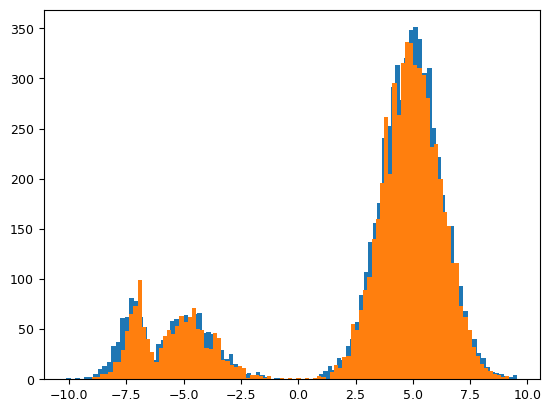

In [138]:
plt.hist(lcb_rs_data["temp_0.33"]["lcb_delta_0.05"]["samples"][:, 0]   , bins=100)
plt.hist(lcb_rs_data["temp_0.33"]["lcb_delta_0.3"]["samples"][:, 0]   , bins=100)

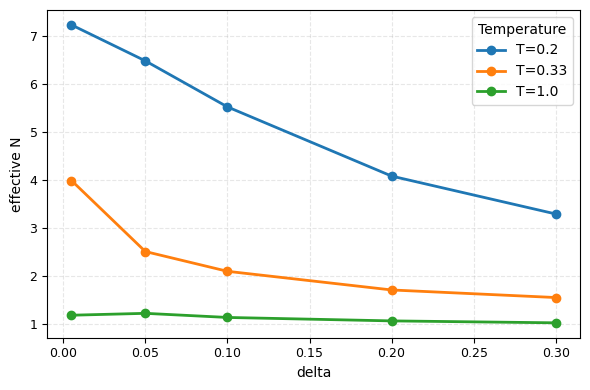

In [162]:
import os, pickle
import matplotlib.pyplot as plt

# adjust if you want a different run
run_dir = "toy_data_runs/20260122_202321_157606"
fname = "lcb_and_rs_results_20_value_epochs.pkl"

with open(os.path.join(run_dir, fname), "rb") as f:
    lcb_data = pickle.load(f)

plt.figure(figsize=(6, 4))
for temp_key, temp_dict in lcb_data.items():
    temp = temp_key.split("_")[1]  # e.g., "0.2"
    deltas = sorted(float(k.split("_")[-1]) for k in temp_dict if k.startswith("lcb_delta_"))
    eff_n = [temp_dict[f"lcb_delta_{d}"]["effective_N"] for d in deltas]
    plt.plot(deltas, eff_n, marker="o", linewidth=2, label=f"T={temp}")

plt.xlabel("delta")
plt.ylabel("effective N")
# plt.xscale("log")  # drop this line if you prefer linear x-axis
plt.grid(True, which="both", linestyle="--", alpha=0.3)
plt.legend(title="Temperature")
plt.tight_layout()
plt.show()


(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)
(7000, 2)


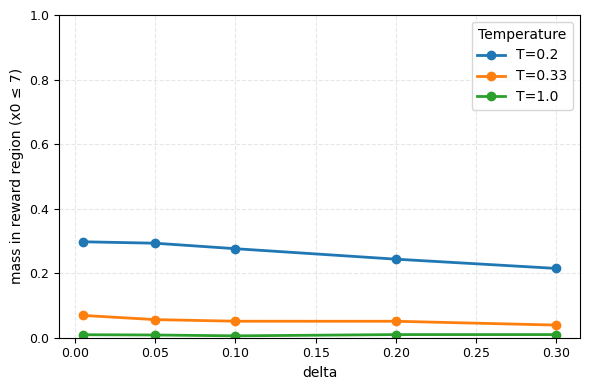

In [165]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt

run_dir = "toy_data_runs/20260122_202321_157606"   # adjust if needed
fname   = "lcb_and_rs_results_20_value_epochs.pkl"

with open(os.path.join(run_dir, fname), "rb") as f:
    lcb_data = pickle.load(f)

def reward_mass(samples):
    return np.mean(samples[:, 0] <= -7)

plt.figure(figsize=(6, 4))
for temp_key, temp_dict in lcb_data.items():
    temp = temp_key.split("_")[1]
    deltas = sorted(float(k.split("_")[-1]) for k in temp_dict if k.startswith("lcb_delta_"))
    masses = []
    for d in deltas:
        samples = temp_dict[f"lcb_delta_{d}"]["samples"]  # shape (num_samples, dim)
        print(samples.shape)
        masses.append(reward_mass(samples))
    plt.plot(deltas, masses, marker="o", linewidth=2, label=f"T={temp}")

plt.xlabel("delta")
plt.ylabel("mass in reward region (x0 ≤ 7)")
plt.ylim(0, 1)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(title="Temperature")
plt.tight_layout()
plt.show()


/var/folders/zk/bk5jkrk11398bfvxps9gbhw00000gn/T/ipykernel_66461/893316294.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("coolwarm")


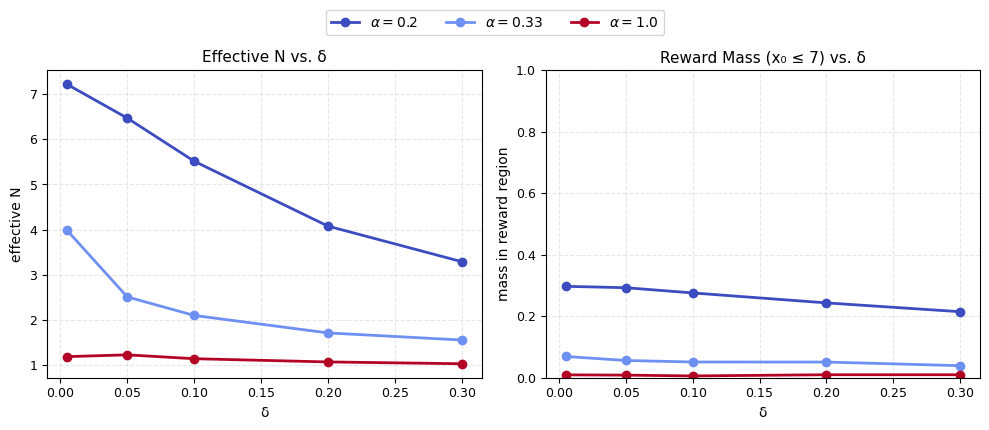

In [ ]:
import os, pickle, numpy as np, matplotlib.pyplot as plt
from matplotlib import cm

run_dir = "toy_data_runs/20260122_202321_157606"   # adjust if needed
fname   = "lcb_and_rs_results_20_value_epochs.pkl"

# choose which deltas to include (order matters)
deltas_to_plot = [0.005, 0.05, 0.1, 0.2, 0.3]

with open(os.path.join(run_dir, fname), "rb") as f:
    lcb_data = pickle.load(f)

def reward_mass(samples):
    return np.mean(samples[:, 0] <= -7)  # reward region

temps = [float(k.split("_")[1]) for k in lcb_data.keys()]
t_min, t_max = min(temps), max(temps)
cmap = cm.get_cmap("coolwarm")
color_for_temp = {
    k: cmap((float(k.split("_")[1]) - t_min) / (t_max - t_min + 1e-9))
    for k in lcb_data
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=False)
handles = []

# Left: effective N vs delta
for temp_key, temp_dict in lcb_data.items():
    color = color_for_temp[temp_key]
    deltas, effs = [], []
    for d in deltas_to_plot:
        key = f"lcb_delta_{d}"
        if key not in temp_dict:
            continue
        deltas.append(d)
        effs.append(temp_dict[key]["effective_N"])
    h, = axes[0].plot(deltas, effs, marker="o", linewidth=2, color=color,
                      label=fr"$\alpha={temp_key.split('_')[1]}$")
    handles.append(h)

axes[0].set_title("Effective N vs. δ")
axes[0].set_xlabel("δ")
axes[0].set_ylabel("effective N")
axes[0].grid(True, linestyle="--", alpha=0.3)

# Right: reward mass vs delta
for temp_key, temp_dict in lcb_data.items():
    color = color_for_temp[temp_key]
    deltas, masses = [], []
    for d in deltas_to_plot:
        key = f"lcb_delta_{d}"
        if key not in temp_dict:
            continue
        deltas.append(d)
        samples = temp_dict[key]["samples"]
        masses.append(reward_mass(samples))
    axes[1].plot(deltas, masses, marker="o", linewidth=2, color=color)

axes[1].set_title("Reward Mass (x₀ ≤ 7) vs. δ")
axes[1].set_xlabel("δ")
axes[1].set_ylabel("mass in reward region")
axes[1].set_ylim(0, 0.6)
axes[1].grid(True, linestyle="--", alpha=0.3)

fig.legend(handles, [h.get_label() for h in handles],
           loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
plt.show()
